# Feature Scaling: Normalization

Normalization is a data preparation step where we change the values of numeric columns to a common scale, without distorting the differences in their ranges or losing information.

There are four common techniques:

1. MinMax scaling
2. Mean normalization
3. MaxAbs scaling
4. Robust scaling

Standardization used the mean and std. Normalization techniques mostly use the min, the max, or the median, so each one reacts differently to outliers.

## MinMax Scaling

MinMax scaling squeezes every value into the range 0 to 1. The smallest value becomes 0 and the largest becomes 1.

$$x_{scaled} = \frac{x - x_{min}}{x_{max} - x_{min}}$$



In [63]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import seaborn as sns

In [4]:
import pandas as pd
data = pd.read_csv(r'D:\coding\wine_data.csv', usecols=[0, 1, 2])
data.head(3)

,class_label,alcohol,malic_acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36


<Axes: xlabel='alcohol', ylabel='malic_acid'>

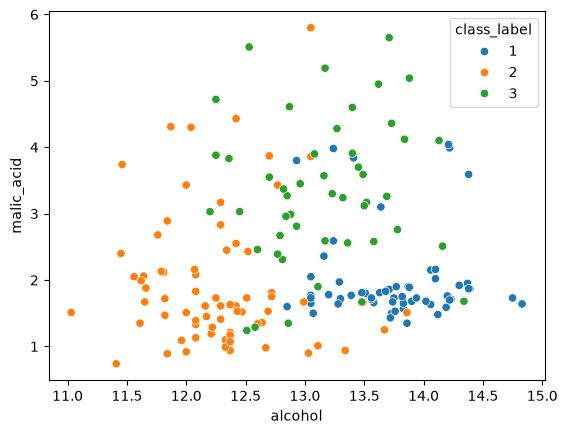

In [22]:
hex_palette = ['#1f77b4', '#ff7f0e', '#2ca02c']

sns.scatterplot(data=data, x='alcohol', y='malic_acid', hue='class_label', palette=hex_palette)


In [36]:
x = data[['alcohol', 'malic_acid']]
y = data[['class_label']]

In [42]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size = 0.2,
    random_state = 42
)

In [43]:
print(x_train.size)
print(x_train.head(3))

284
     alcohol  malic_acid
158    14.34        1.68
137    12.53        5.51
98     12.37        1.07


In [44]:
print(x_test.size)
print(x_test.head(3))

72
     alcohol  malic_acid
19     13.64        3.10
45     14.21        4.04
140    12.93        2.81


In [50]:
mm_scaler = MinMaxScaler()
xtrain_scaled = mm_scaler.fit_transform(x_train).reshape(-1, 2)
xtest_scaled = mm_scaler.transform(x_test).reshape(-1, 2)

In [52]:
xtrain_scaled[:4]

array([[0.87105263, 0.16089613],
       [0.39473684, 0.94093686],
       [0.35263158, 0.03665988],
       [0.64473684, 0.15885947]])

In [53]:
xtest_scaled[:4]

array([[0.68684211, 0.45010183],
       [0.83684211, 0.64154786],
       [0.5       , 0.3910387 ],
       [0.71052632, 0.12423625]])

In [60]:
x_train.describe()

,alcohol,malic_acid
count,142.000000,142.000000
mean,12.979085,2.373521
std,0.820116,1.143934
min,11.030000,0.890000
25%,12.332500,1.615000
50%,13.010000,1.875000
75%,13.677500,3.135000
max,14.830000,5.800000


In [62]:
pd.DataFrame(xtrain_scaled).describe()

,0,1
count,142.000000,142.000000
mean,0.512917,0.302143
std,0.215820,0.232980
min,0.000000,0.000000
25%,0.342763,0.147658
50%,0.521053,0.200611
75%,0.696711,0.457230
max,1.000000,1.000000


Before scaling, the minimum and maximum values lie outside the 0 to 1 range after applying the MinMaxScaler, they are successfully bounded between 0 and 1.

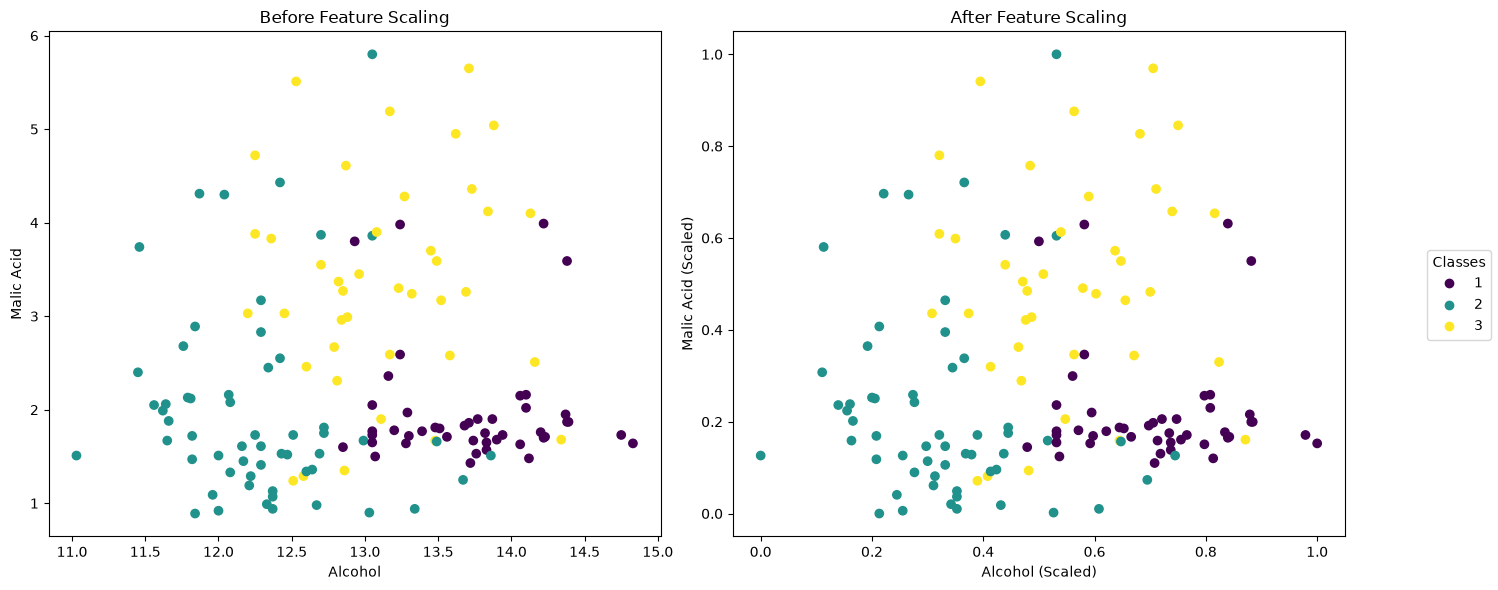

In [96]:
scaled_df = pd.DataFrame(xtrain_scaled, columns=x_train.columns)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

# Plot 1: Before Scaling
scatter1 = ax[0].scatter(
    data=x_train, 
    x='alcohol', 
    y='malic_acid', 
    c=y_train['class_label'], 
    
)
ax[0].set_title('Before Feature Scaling')
ax[0].set_xlabel('Alcohol')
ax[0].set_ylabel('Malic Acid')

# Plot 2: After Scaling
scatter2 = ax[1].scatter(
    data=scaled_df, 
    x='alcohol', 
    y='malic_acid', 
    c=y_train['class_label'], 
)
ax[1].set_title('After Feature Scaling')
ax[1].set_xlabel('Alcohol (Scaled)')
ax[1].set_ylabel('Malic Acid (Scaled)')

handles, labels = scatter1.legend_elements()
fig.legend(handles, labels, loc='right', title="Classes")


plt.tight_layout()
plt.subplots_adjust(right=0.9) 
plt.show()


### After scaling, the data is squeezed into a square of area 1.

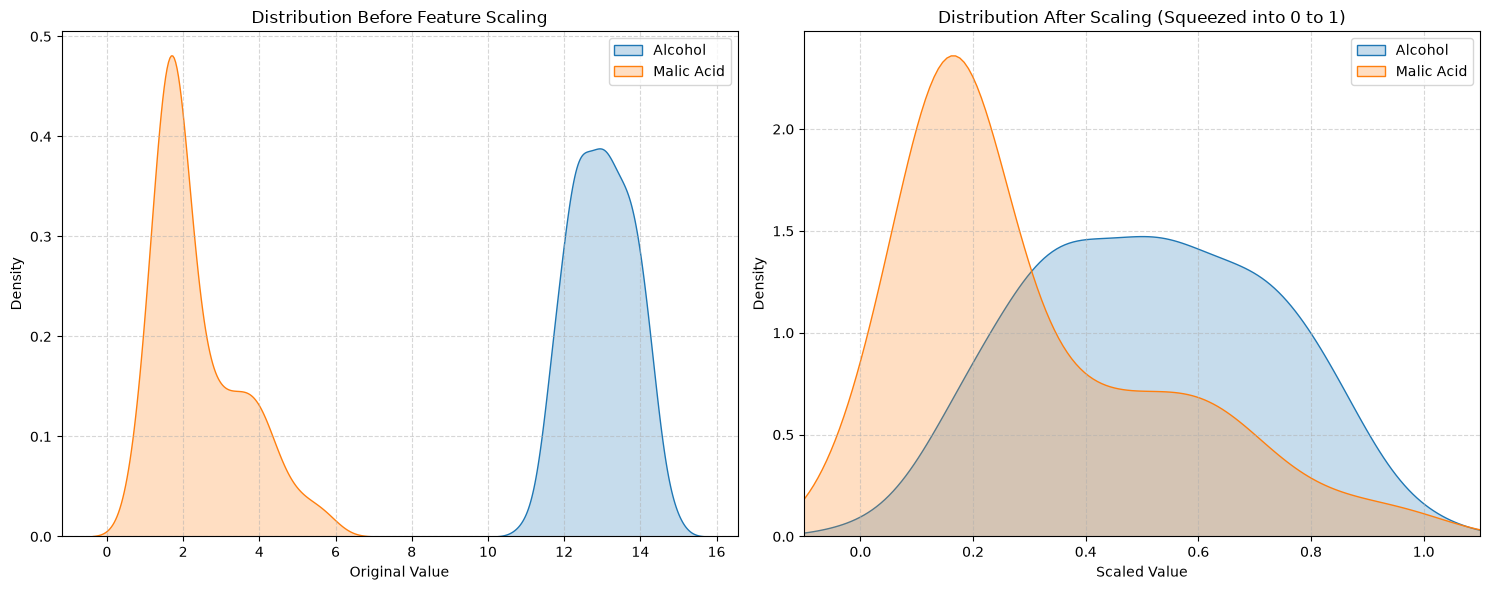

In [104]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

# 1. Before Scaling (Original Scale)

sns.kdeplot(data=x_train, x='alcohol', label='Alcohol', fill=True, ax=ax[0])
sns.kdeplot(data=x_train, x='malic_acid', label='Malic Acid', fill=True, ax=ax[0])

ax[0].set_title('Distribution Before Feature Scaling')
ax[0].set_xlabel('Original Value')
ax[0].set_ylabel('Density')
ax[0].legend()
ax[0].grid(True, linestyle='--', alpha=0.5)


# 2. After Scaling (Bounded Overlap)

sns.kdeplot(data=scaled_df, x='alcohol', label='Alcohol', fill=True, ax=ax[1])
sns.kdeplot(data=scaled_df, x='malic_acid', label='Malic Acid', fill=True, ax=ax[1])

# Constrain the view close to the scaled limits [0, 1] to avoid referencing
ax[1].set_xlim(-0.1, 1.1)

ax[1].set_title('Distribution After Scaling (Squeezed into 0 to 1)')
ax[1].set_xlabel('Scaled Value')
ax[1].set_ylabel('Density')
ax[1].legend()
ax[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#  The Vulnerability of MinMax Scaling: The Outlier Compression Effect

## 1. Introduction
While **MinMax Normalization (Rescaling)** is highly effective for bounding data within a fixed, intuitive range like $[0, 1]$, it suffers from a significant limitation: **extreme sensitivity to outliers**. 

Because the scaling transformation is entirely dependent on the single absolute minimum ($X_{min}$) and maximum ($X_{max}$) values in the dataset, a solitary anomalous point can radically warp the relative distances of all other data points. Instead of preserving a meaningful distribution variance, the normal data structure gets heavily **compressed ("squashed")** into a tiny sub-region of the target area.

---

## 2. Mathematical Mechanics: Why Does It Squash?

To understand why this happens, look at the standard MinMax formula for a feature vector $X$:

$$X_{scaled} = \frac{X - X_{min}}{X_{max} - X_{min}}$$

When an extreme upper outlier is introduced into the dataset, it dynamically shifts the value of $X_{max}$ to an artificially high number. Let's analyze the impact this has on the formula:

1. **Inflated Denominator:** The range term $(X_{max} - X_{min})$ becomes massive.
2. **Diminished Ratios:** For all standard, non-outlier data points, their actual values ($X$) are very small relative to the new, giant $X_{max}$. As a result, the numerator $(X - X_{min})$ stays comparatively tiny.
3. **Compression toward Zero:** Dividing a small numerator by a massive denominator forces the $X_{scaled}$ output for almost *all* regular data points to fall exceptionally close to `0`. 

### The Resulting Plot Distortion
* **The Outlier:** Sits isolated at exactly `(1.0, 1.0)`.
* **The Normal Data:** Entire valuable distribution of classes 1, 2, and 3 loses its visual resolution and gets violently squeezed into a small corner near `(0.0, 0.0)`. The model loses its ability to easily distinguish variance among normal samples because their relative numeric spread is heavily suppressed.


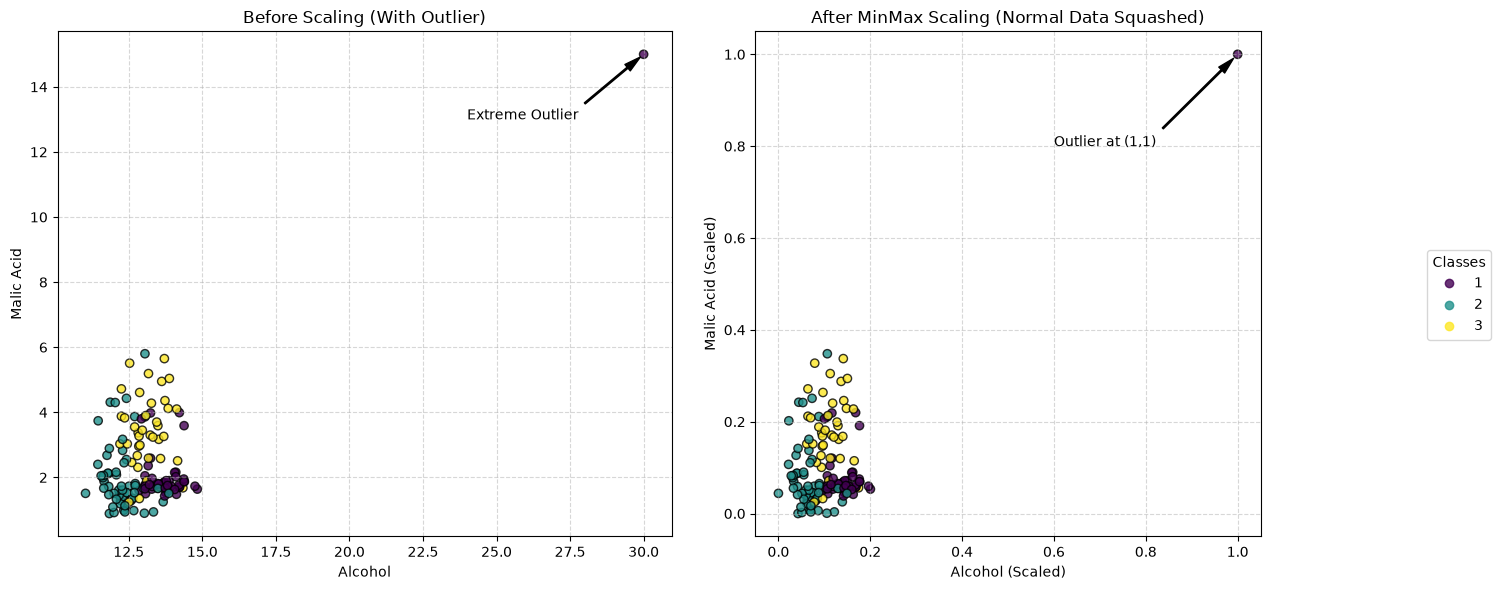

In [110]:
# Used AI for these graphs


outlier_x = pd.DataFrame([[30.0, 15.0]], columns=['alcohol', 'malic_acid'])
outlier_y = pd.DataFrame([[1]], columns=['class_label'])

x_train_with_outlier = pd.concat([x_train, outlier_x], ignore_index=True)
y_train_with_outlier = pd.concat([y_train, outlier_y], ignore_index=True)

# 2. Re-scale using MinMaxScaler with the outlier included
scaler = MinMaxScaler()
xtrain_scaled_outlier = scaler.fit_transform(x_train_with_outlier)
scaled_df_outlier = pd.DataFrame(xtrain_scaled_outlier, columns=x_train.columns)

# 3. Plot the visualization
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

# --- Plot 1: Before Scaling with Outlier ---
scatter1 = ax[0].scatter(
    data=x_train_with_outlier, 
    x='alcohol', 
    y='malic_acid', 
    c=y_train_with_outlier['class_label'], 
    cmap='viridis', 
    edgecolor='k', 
    alpha=0.8
)
# Annotate the outlier so it's obvious
ax[0].annotate('Extreme Outlier', xy=(30.0, 15.0), xytext=(24, 13),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

ax[0].set_title('Before Scaling (With Outlier)')
ax[0].set_xlabel('Alcohol')
ax[0].set_ylabel('Malic Acid')
ax[0].grid(True, linestyle='--', alpha=0.5)

# --- Plot 2: After MinMax Scaling (Squashed Data) ---
scatter2 = ax[1].scatter(
    data=scaled_df_outlier, 
    x='alcohol', 
    y='malic_acid', 
    c=y_train_with_outlier['class_label'], 
    cmap='viridis', 
    edgecolor='k', 
    alpha=0.8
)
# Annotate where the outlier ended up (at exactly 1.0, 1.0)
ax[1].annotate('Outlier at (1,1)', xy=(1.0, 1.0), xytext=(0.6, 0.8),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

ax[1].set_title('After MinMax Scaling (Normal Data Squashed)')
ax[1].set_xlabel('Alcohol (Scaled)')
ax[1].set_ylabel('Malic Acid (Scaled)')
ax[1].grid(True, linestyle='--', alpha=0.5)

# Force the 1x1 square layout to see the empty space created
ax[1].set_aspect('equal', adjustable='box')
ax[1].set_xlim(-0.05, 1.05)
ax[1].set_ylim(-0.05, 1.05)

# Add Legend
handles, labels = scatter1.legend_elements()
fig.legend(handles, labels, loc='right', title="Classes")
plt.tight_layout()
plt.subplots_adjust(right=0.88)

plt.show()
